# K-Means Clustering from Scratch

## 1. Overview and Intuition
**K-Means** is one of the most popular unsupervised clustering algorithms. Given an unlabeled dataset $X = \{x_1, x_2, \dots, x_N\}$ in $\mathbb{R}^D$ and a specified number of clusters $K$, the goal is to partition the $N$ observations into $K$ disjoint clusters $S = \{S_1, S_2, \dots, S_K\}$ such that the within-cluster sum of squares (WCSS / inertia) is minimized.

### Mathematical Formulation
The objective function (inertia) is:
$$\mathcal{J} = \sum_{k=1}^K \sum_{x \in S_k} \|x - \mu_k\|^2$$

where $\mu_k$ is the geometric centroid (mean) of cluster $S_k$:
$$\mu_k = \frac{1}{|S_k|} \sum_{x \in S_k} x$$

### The Lloyd's Algorithm (Expectation-Maximization Style):
1. **Initialization:** Select $K$ initial centroids $\mu_1, \dots, \mu_K$ (e.g., random samples from $X$).
2. **Assignment Step (E-step):** Assign each observation $x_i$ to the nearest centroid using Euclidean distance:
   $$c_i = \arg\min_{k \in \{1, \dots, K\}} \|x_i - \mu_k\|_2$$
3. **Update Step (M-step):** Recompute the centroid of each cluster as the mean of points assigned to it.
4. **Convergence Check:** Repeat steps 2 and 3 until centroids stabilize (displacement $< \epsilon$) or a maximum number of iterations is reached.

**Time Complexity:** $\mathcal{O}(I \cdot K \cdot N \cdot D)$, where $I$ = iterations, $K$ = clusters, $N$ = data points, $D$ = dimensions.  
**Space Complexity:** $\mathcal{O}(N \cdot D + K \cdot D)$.

## 2. Implementation in Pure Python (Zero Dependencies)

In [2]:
import math
import random
from typing import List, Tuple


def euclidean_distance(point_a: List[float], point_b: List[float]) -> float:
    """Calculates the Euclidean (L2) distance between two D-dimensional points."""
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(point_a, point_b)))


def update_centroids(
    clusters: List[int], X: List[List[float]], k: int, old_centroids: List[List[float]]
) -> List[List[float]]:
    """Recomputes centroids as the mean of points in each cluster.

    If a cluster becomes empty, it retains its previous centroid to avoid division by zero.
    """
    num_features = len(X[0])
    new_centroids: List[List[float]] = []

    for cluster_idx in range(k):
        cluster_points = [X[i] for i, c in enumerate(clusters) if c == cluster_idx]
        if not cluster_points:
            # Empty cluster fallback: retain previous centroid
            new_centroids.append(list(old_centroids[cluster_idx]))
            continue

        mean_point = [
            sum(cluster_points[row][col] for row in range(len(cluster_points))) / len(cluster_points)
            for col in range(num_features)
        ]
        new_centroids.append(mean_point)

    return new_centroids


def has_converged(
    old_centroids: List[List[float]], new_centroids: List[List[float]], tolerance: float
) -> bool:
    """Checks if all centroids have shifted by less than the tolerance threshold."""
    return all(
        euclidean_distance(c_old, c_new) < tolerance
        for c_old, c_new in zip(old_centroids, new_centroids)
    )


def kmeans(
    X: List[List[float]],
    k: int,
    max_iters: int = 100,
    tolerance: float = 1e-4,
    seed: int = 42,
) -> Tuple[List[List[float]], List[int]]:
    """Executes K-Means clustering algorithm on dataset X.

    Args:
        X: Dataset as a list of D-dimensional data points.
        k: Number of clusters.
        max_iters: Maximum iterations permitted.
        tolerance: Centroid shift threshold for early convergence.
        seed: Random seed for reproducible initialization.

    Returns:
        A tuple containing (final_centroids, cluster_assignments).
    """
    if k > len(X):
        raise ValueError("Number of clusters k cannot exceed number of samples N.")

    rng = random.Random(seed)
    centroids = [list(pt) for pt in rng.sample(X, k)]
    assignments: List[int] = [0] * len(X)

    for _ in range(max_iters):
        # 1. Assignment Step
        for i, point in enumerate(X):
            distances = [euclidean_distance(point, c) for c in centroids]
            assignments[i] = distances.index(min(distances))

        # 2. Update Step
        new_centroids = update_centroids(assignments, X, k, centroids)

        # 3. Convergence Check
        if has_converged(centroids, new_centroids, tolerance):
            centroids = new_centroids
            break

        centroids = new_centroids

    return centroids, assignments

## 3. Demonstration on Synthetic Multi-Cluster Data

In [3]:
# Generate synthetic 2D data with 3 distinct clusters
random.seed(42)

cluster_1 = [[random.gauss(2.0, 0.6), random.gauss(2.0, 0.6)] for _ in range(40)]
cluster_2 = [[random.gauss(8.0, 0.7), random.gauss(3.0, 0.7)] for _ in range(40)]
cluster_3 = [[random.gauss(5.0, 0.5), random.gauss(8.0, 0.5)] for _ in range(40)]

X_synthetic = cluster_1 + cluster_2 + cluster_3
k = 3

centroids, assignments = kmeans(X_synthetic, k=k, max_iters=100, seed=42)

print(f"Total data points: {len(X_synthetic)}")
for idx, centroid in enumerate(centroids):
    cluster_size = assignments.count(idx)
    print(f"Cluster {idx}: Centroid = [{centroid[0]:.3f}, {centroid[1]:.3f}] | Count = {cluster_size}")

Total data points: 120
Cluster 0: Centroid = [5.009, 8.133] | Count = 40
Cluster 1: Centroid = [8.172, 3.034] | Count = 40
Cluster 2: Centroid = [2.054, 1.991] | Count = 40


## 4. Visualizing Results with Matplotlib

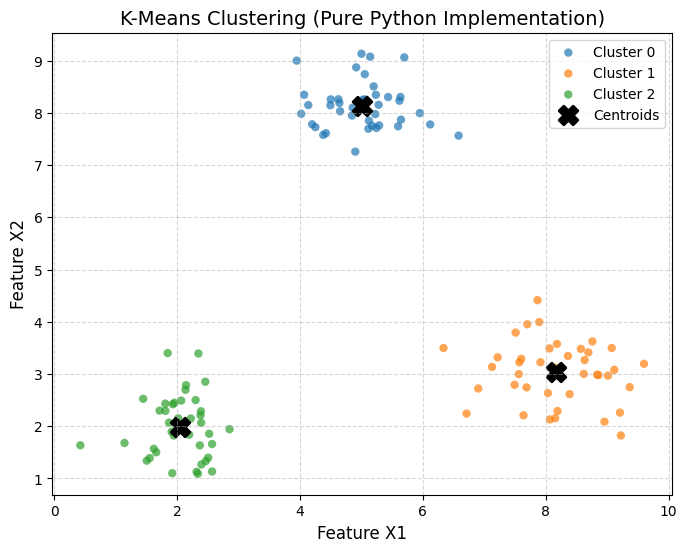

In [4]:
try:
    import matplotlib.pyplot as plt

    colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
    fig, ax = plt.subplots(figsize=(8, 6))

    # Plot clustered data points
    for cluster_idx in range(k):
        pts = [X_synthetic[i] for i, c in enumerate(assignments) if c == cluster_idx]
        xs = [p[0] for p in pts]
        ys = [p[1] for p in pts]
        ax.scatter(xs, ys, color=colors[cluster_idx % len(colors)], label=f"Cluster {cluster_idx}", alpha=0.7, edgecolors="none")

    # Plot centroids
    c_xs = [c[0] for c in centroids]
    c_ys = [c[1] for c in centroids]
    ax.scatter(c_xs, c_ys, color="black", marker="X", s=180, linewidths=2, label="Centroids")

    ax.set_title("K-Means Clustering (Pure Python Implementation)", fontsize=14)
    ax.set_xlabel("Feature X1", fontsize=12)
    ax.set_ylabel("Feature X2", fontsize=12)
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.show()
except ImportError:
    print("matplotlib is not installed in the environment. Skipping visual plot.")